# Historic Jeddah Building Metadata
## Data Cleaning and Exploratory Data Analysis

This notebook prepares and explores a metadata collection for heritage buildings in **Historic Jeddah (Al-Balad)**. It focuses on data quality, geographic coverage, categorical consistency, numerical summaries, and the availability of historical descriptions.

### Notebook objectives

- Load the building metadata from its public CSV source.
- remove empty rows and irrelevant columns;
- standardize data types and inconsistent labels;
- examine geographic and categorical distributions;
- visualize heritage-building locations; and
- assess the coverage of historical descriptions and their sources.

### Workflow

1. [Setup and data loading](#1-setup-and-data-loading)
2. [Data cleaning](#2-data-cleaning)
3. [Exploratory data analysis](#3-exploratory-data-analysis)
4. [Summary of findings](#4-summary-of-findings)

---

## 1. Setup and Data Loading

The first cells import the required analysis and visualization libraries, then load the CSV file into a pandas DataFrame. The CSV begins after four metadata rows, so `header=4` is used when reading the file.


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

In [ ]:
file_path = "https://raw.githubusercontent.com/omar-ys/albalad_data/main/MDT-001_Building_Metadata_Template.csv"
df = pd.read_csv(file_path, header=4)

## 2. Data Cleaning

The raw file contains many fully empty rows and requires several consistency checks before analysis. This section previews the data, removes irrelevant columns and blank records, assigns suitable data types, and evaluates missing and duplicate values.

### 2.1 Initial Data Preview

A small preview confirms that the file was loaded correctly and shows the available building attributes.


In [ ]:
df.head()

### 2.2 Remove Unnamed Columns

CSV exports often include empty columns named `Unnamed: ...`. These columns do not contain analytical information and are removed before continuing.


In [ ]:
df = df.loc[:, ~df.columns.str.contains('^Unnamed')]

In [ ]:
df.head()

### 2.3 Validate the Schema and Assign Data Types

The schema is inspected before and after conversion. Repeated low-cardinality text fields are converted to `category`, free-text fields use pandas' nullable `string` type, and the two count fields use nullable integers.


In [ ]:
df.info()

In [ ]:
df["Number of Floors"] = df["Number of Floors"].astype("Int64")
df["Estimated Images"] = df["Estimated Images"].astype("Int64")

# Low-cardinality repeated text -> category (memory + enables ordered/groupby semantics)
cat_cols = ["District", "Area", "City", "Building Category", "Architectural Style",
            "Construction Material", "Lighting Condition", "Reference Source"]
df[cat_cols] = df[cat_cols].astype("category")

# Free-text fields -> pandas nullable "string" dtype instead of generic object
str_cols = df.select_dtypes(include=['object']).columns
df[str_cols] = df[str_cols].astype("string")

df.info()

### 2.4 Remove Fully Empty Rows

The original file contains 993 rows, but most are blank template rows. The shape is checked before and after dropping rows where every value is missing.


In [ ]:
df.shape

In [ ]:
df = df.dropna(how="all").reset_index(drop=True)

In [ ]:
df.shape

In [ ]:
df.isna().sum()

### 2.5 Missing Values and Duplicate Records

The missing-value check distinguishes complete core metadata from optional historical fields. In the current output, all core building and location fields are populated, while some historical descriptions and source references are missing.

The duplicate check below verifies whether any complete rows are repeated.


In [ ]:
df.duplicated().sum()

## 3. Exploratory Data Analysis

The exploratory analysis is organized into four themes:

1. geographic scope and street-name consistency;
2. categorical distributions and label normalization;
3. numeric summaries; and
4. historical-description coverage.


### 3.1 Geographic Scope

#### 3.1.1 Street-Name Consistency

Street frequencies are reviewed first because inconsistent spelling, punctuation, word order, and transliteration can incorrectly split a single street into multiple categories.


In [ ]:

df["Street"].value_counts()

> **Observed inconsistencies before normalization**
>
> - `Al-Alawi Street` and `Al Alawi Street`
> - `Ayyas Bin Rabab` and `Ayyas Ibn Rabab`
> - `Abu Anbah Street` and `street Abu Anba`
> - `Alzahab` and `street Al-Dhahab`
> - `Qabil` and `Zuqaq Qabil`
>
> The following cell converts placeholder text to missing values, standardizes casing and hyphens, and maps known variants to preferred street names.


In [ ]:
df["Street"] = df["Street"].replace(
    ["Null", "nan", "None", ""], np.nan
)  # Handles missing values

# Standardize hyphens, casing, and common prefixes/suffixes
df["Street"] = (
    df["Street"]
    .str.replace("-", " ", regex=False)  # Turn 'Al-Alawi' into 'Al Alawi'
    .str.lower()  # Convert all to lowercase first for easier matching
    .str.title()  # Convert back to Title Case
)

# Map typos, abbreviations, and variations to a single unified name
street_mapping = {
    "Street Abu Anba": "Abu Anbah Street",
    "Abu Anbah Street": "Abu Anbah Street",
    "Al Alawi Street": "Al-Alawi Street",
    "Street Al Dhahab": "Al-Dhahab Street",
    "Alzahab": "Al-Dhahab Street",
    "Street Zuqaq Bisash": "Zuqaq Bisash",
    "Ayyas Bin Rabab": "Ayyas Ibn Rabab",
    "Al Bazan": "Zuqaq Bazan",
}

df["Street"] = df["Street"].replace(street_mapping)

# Re-run value counts (excluding missing values if desired)
df["Street"].value_counts(dropna=True)

#### 3.1.2 District, Area, and City Coverage

After street-name normalization, the notebook summarizes the geographic hierarchy to verify the number of records assigned to each district, area, and city.


In [ ]:
df[["District","Area","City"]].apply(pd.Series.value_counts)

#### 3.1.3 Buildings by District

A horizontal count plot makes differences in district representation easier to compare.


In [ ]:
plt.figure(figsize=(10, 5))

sns.countplot(
    y=df['District'],
    order=df['District'].value_counts().index,
    palette='viridis'
)

plt.title('Distribution of Buildings by District')
plt.xlabel('Count')
plt.ylabel('District')

plt.show()

#### 3.1.4 Coordinate Extraction

If separate latitude and longitude fields are unavailable, they are derived from the combined `GPS Coordinates` string. Invalid or missing coordinate strings are converted to missing numeric values.


In [ ]:
if 'Latitude' not in df.columns or 'Longitude' not in df.columns:
    def extract_lat_lon(coord_string):
        if pd.isna(coord_string):
            return pd.Series([np.nan, np.nan])
        try:
            parts = str(coord_string).split(',')
            return pd.Series([float(parts[0].strip()), float(parts[1].strip())])
        except:
            return pd.Series([np.nan, np.nan])

    df[['Latitude', 'Longitude']] = df['GPS Coordinates'].apply(extract_lat_lon)

#### 3.1.5 Interactive Heritage-Building Map

The extracted coordinates are plotted on a free Carto/Mapbox basemap. Hover information connects each point to its building name, identifier, and category.


In [ ]:
fig2 = px.scatter_mapbox(
    df,
    lat="Latitude",
    lon="Longitude",
    hover_name="Building Name (English)", # Shows building name when you hover
    hover_data=["Building ID", "Building Category"],
    color="District",
    zoom=14.75,
    height=600,
    title="Interactive Map of Heritage Buildings"
)

# Use OpenStreetMap style (free, no token required)
fig2.update_layout(mapbox_style="carto-positron")
fig2.update_layout(margin={"r":0,"t":40,"l":0,"b":0})

fig2.show()

#### Static Map Preview

The image below is a static preview of the geographic output.

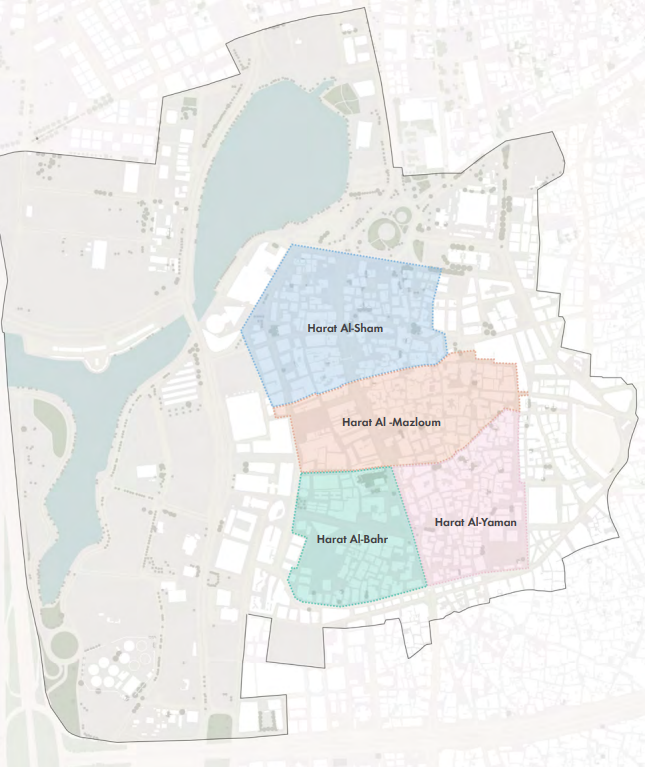




**Map interpretation.** The spatial view helps validate whether coordinates fall within the expected Historic Jeddah area and makes district clustering easier to inspect. The interactive Plotly map above should be used for detailed hovering and record-level inspection.


### 3.2 Categorical Distributions

This section examines repeated descriptive fields, including building category, architectural style, construction material, lighting condition, and reference source. Frequency tables reveal dominant values and expose inconsistent labels.


In [ ]:
for col in ["Building Category","Architectural Style","Construction Material","Lighting Condition","Reference Source"]:
    print(df[col].value_counts(dropna=False))

#### 3.2.1 Construction-Material Consistency

The initial frequency tables reveal two formatting issues:

- **Construction Material:** equivalent material lists use inconsistent line breaks and spacing.
- **Building Category:** `School` and `school` appear as separate categories because of casing.

The next cells inspect and normalize the construction-material field by trimming each line and joining the components into a consistent comma-separated value.


In [ ]:
df["Construction Material"].value_counts()

In [ ]:
df["Construction Material"] = (
    df["Construction Material"]
    .astype(str)
    .apply(lambda x: ", ".join([part.strip() for part in x.splitlines() if part.strip()]))
)

In [ ]:
df["Construction Material"].value_counts()

#### 3.2.2 Architectural-Element Consistency

Architectural-element descriptions can list the same features in different orders or with inconsistent punctuation. The normalization function removes trailing periods, eliminates duplicate items, and sorts the remaining elements to create comparable category labels.


In [ ]:
df["Architectural Elements"].value_counts(dropna=False)

In [ ]:
def normalize_elements(x):
    if pd.isna(x):
        return np.nan

    x = x.strip()

    # Keep "None" categories as they are
    if x.lower().startswith("none"):
        return x

    # Split, remove whitespace and periods
    elements = [e.strip().rstrip(".") for e in x.split(",")]

    # Remove duplicates while preserving unique values
    elements = sorted(set(elements))

    return ", ".join(elements)

df["Architectural Elements"] = df["Architectural Elements"].apply(normalize_elements)

df["Architectural Elements"].value_counts(dropna=False)

#### 3.2.3 Building-Category Distribution

A count plot summarizes the relative representation of each building category after the categorical review.


In [ ]:
# Plot 2: Distribution by Building Category
plt.figure()

sns.countplot(
    y=df['Building Category'],
    order=df['Building Category'].value_counts().index,
)

plt.title('Distribution of Building Category')
plt.xlabel('Count')
plt.ylabel('Category')

plt.show()

> **Current category pattern:** Historic houses form the largest building category in the dataset. Smaller categories include gates, hotels, mosques, ribats, a museum, a school, and other heritage-building types.


### 3.3 Numeric Summaries

The two numeric fields describe the number of floors and the estimated image volume associated with each building record. Summary statistics are used to identify central values, ranges, and potentially unusual entries.

#### 3.3.1 Number of Floors

The first summary describes floor counts. Records with a value of zero are then listed for review because they may represent gates, grouped records, or non-building structures rather than conventional multi-floor buildings.


In [ ]:
df["Number of Floors"].describe()

In [ ]:
df[df['Number of Floors'] == 0]['Building ID']

#### 3.3.2 Estimated Image Volume

The estimated number of images per building is summarized separately because it reflects documentation effort rather than a physical building characteristic.


In [ ]:
df["Estimated Images"].describe()

#### 3.3.3 Distribution Plots

Side-by-side histograms show the distribution of floor counts and estimated images. These plots make skew, concentration, and extreme values easier to identify than summary statistics alone.


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].hist(df["Number of Floors"], bins=range(0, 7), edgecolor="white")
axes[0].set_title("Number of Floors")
axes[1].hist(df["Estimated Images"], bins=15, edgecolor="white")
axes[1].set_title("Estimated Images per Building")
plt.tight_layout()

### 3.4 Historical Descriptions and Sources

Historical descriptions enrich the geographic metadata with cultural and architectural context. The following cells inspect the available text, review the associated source references, and calculate coverage for both fields.


In [ ]:
df["Historical Description"].dropna()

In [ ]:
df["Source of Historical Description"].dropna()

#### 3.4.1 Coverage Counts

The final two cells count how many records contain a historical description and how many provide a source for that description.


In [ ]:
df["Historical Description"].dropna().count()

In [ ]:
df["Source of Historical Description"].dropna().count()

---

## 4. Summary of Findings

| Analysis area | Current notebook result |
|---|---|
| Usable dataset size | **52 building records** and **18 columns** after fully empty rows are removed |
| Duplicate rows | **0** complete duplicate records |
| Historical descriptions | **46 of 52 records** contain a description |
| Description sources | **29 of 52 records** contain a source reference |
| Dominant district | **Harat Al-Mazloum** has the largest number of records |
| Dominant building category | **Historic House** is the most frequent category |
| Architectural style | All current records use **Traditional Hijazi Architecture** |
| Floor count | Median: **3 floors**; observed range: **0–5** |
| Estimated images | Median: **61.5 images**; observed range: **3–327** |

### Data-Quality Notes

- Street-name variants were consolidated using a targeted mapping.
- Construction-material formatting was standardized.
- Architectural-element lists were normalized to reduce duplicate category labels.
- The district value `Null`, zero-floor records, and the `School`/`school` category difference remain useful candidates for manual review.
- Historical source coverage is lower than description coverage, so source completion should be prioritized before using the dataset for citation-sensitive applications.

---

*End of notebook.*
